# Digit MNIST – ANN (Artificial Neural Network)

**Goal:** Look at a handwritten digit image (0–9) and predict which number it is.

| Item | Value |
|---|---|
| Dataset | MNIST (Keras built-in) – 60,000 train + 10,000 test images |
| Image size | 28 × 28 pixels, grayscale (0 = black, 255 = white) |
| Classes | 10 (Zero … Nine) |
| Model | Dense ANN: 784 → 256 → 64 → 64 → 10 |

**Flow:** Import → Load data → Visualize → Reshape 3D→2D → One-hot labels → Build model → Compile → Train → Evaluate → Predict → Confusion matrix → Curves → Single image test

In [4]:
%pip install tensorflow numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
# ===================== 1. IMPORT LIBRARIES =====================
# Updated for new versions of TensorFlow / Keras / matplotlib.
# If a library is missing, install it once in a cell:  !pip install tensorflow seaborn scikit-learn

# ---- Basic Libraries ----
import numpy as np          # numbers & arrays (matrix calculations)
import pandas as pd         # tables (DataFrame) - read CSV, view data

# ---- Visualization libraries ----
import matplotlib.pyplot as plt   # draw images, line graphs
import seaborn as sns             # nicer charts - used for confusion-matrix heatmap
# (pydot removed - it was only needed for drawing model diagrams and is not used here)

# ---- Evaluation library (scikit-learn) ----
from sklearn.metrics import confusion_matrix        # table of correct vs wrong predictions per class
from sklearn.metrics import classification_report   # precision / recall / f1 for each class

# ---- Deep Learning libraries (TensorFlow / Keras) ----
import tensorflow as tf
from tensorflow import keras                         # keras that comes inside TensorFlow
from tensorflow.keras import layers                  # Dense, Dropout, BatchNormalization layers
from tensorflow.keras.datasets import mnist          # built-in handwritten digit dataset (0-9)
from tensorflow.keras.utils import to_categorical    # converts label 3 -> [0,0,0,1,0,0,0,0,0,0] (one-hot)

## 2. Load the dataset
`mnist.load_data()` returns **two tuples** → (train images, train labels), (test images, test labels).
The model learns from the training data; the test data is used to check how accurately it predicts images it has never seen.

In [6]:
#Digit MNIST dataset
# X = images (input), y = labels (correct answer 0-9)
# X_train_digit : (60000, 28, 28)  -> 60,000 images, each 28x28 pixels
# y_train_digit : (60000,)         -> 60,000 labels
# X_test_digit  : (10000, 28, 28)  -> 10,000 images for testing
# y_test_digit  : (10000,)
(X_train_digit, y_train_digit), (X_test_digit, y_test_digit) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 7s 1us/step


In [7]:
# See one image as raw numbers: a 28x28 grid of pixel values
# 0 = black background, up to 255 = bright white (the pen stroke)
X_train_digit[1]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  51, 159, 253, 159,  50,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  48, 238, 252, 252, 252, 237,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  

In [8]:
# Label of the 4th test image (index starts from 0) -> answer is the digit itself
y_test_digit[3]

np.uint8(0)

## 3. Visualize some images
Show the first 15 training images in a grid, with each image's label name below it.

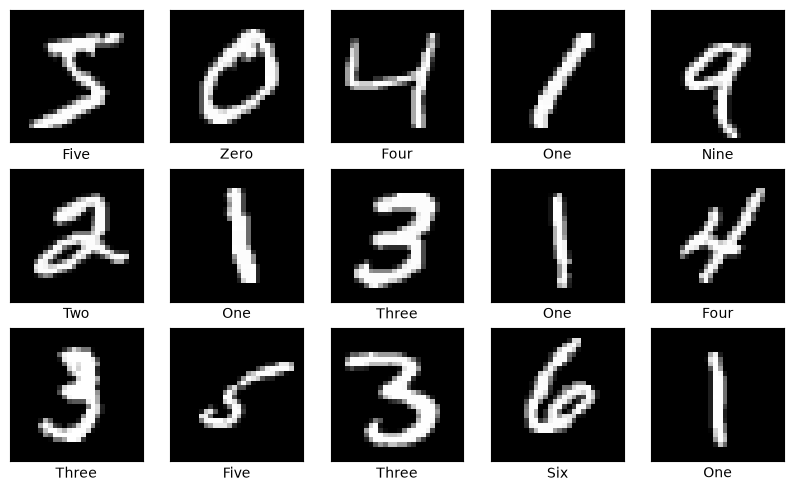

In [9]:
#Names of numbers in the dataset in order
# index 0 -> 'Zero', index 1 -> 'One' ... index 9 -> 'Nine'
col_names = ['Zero','One','Two','Three','Four','Five','Six','Seven','Eight','Nine']

#Visualizing the digits
plt.figure(figsize=(10,10))                    # canvas size 10x10 inches
for i in range(15):                            # first 15 images
    plt.subplot(5,5,i+1)                       # 5 rows x 5 cols grid, position i+1
    plt.xticks([])                             # hide x-axis numbers
    plt.yticks([])                             # hide y-axis numbers
    plt.imshow(X_train_digit[i], cmap='gray')  # show image in black & white
    plt.xlabel(col_names[y_train_digit[i]])    # label below image, e.g. 'Five'
plt.show()

In [10]:
# Shape check: (number of images, height, width)
X_train_digit.shape

(60000, 28, 28)

## 4. Preprocessing – Converting 3D → 2D
A Dense (ANN) layer can only take a **flat list of numbers**, not a 2D picture.
So every 28×28 image is flattened into **784 numbers** (28 × 28 = 784).
`(60000, 28, 28)` → `(60000, 784)`

In [11]:
# Flatten each 28x28 image into one row of 784 pixels
X_train_digit = X_train_digit.reshape(60000, 784)   # 60000 rows x 784 columns
X_test_digit = X_test_digit.reshape(10000, 784)     # 10000 rows x 784 columns

# TIP (not in the original): scaling pixels to 0-1 usually trains faster & more stably:
# X_train_digit = X_train_digit / 255.0
# X_test_digit  = X_test_digit  / 255.0

In [12]:
# Confirm new shape -> (60000, 784)
X_train_digit.shape

(60000, 784)

In [13]:
# Test labels are still plain numbers (7, 2, 1, ...) - not encoded yet
y_test_digit

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,), dtype=uint8)

## 5. One-hot encoding the labels
The output layer has 10 neurons (one per digit), so each label must also be a list of 10 values:

`5` → `[0, 0, 0, 0, 0, 1, 0, 0, 0, 0]` (1 only at index 5)

This one-hot format is what the `categorical_crossentropy` loss expects.

In [14]:
#Encoding Digit MNIST Labels
# to_categorical: number -> one-hot vector of length 10
y_train_digit = to_categorical(y_train_digit, num_classes=10)   # (60000,) -> (60000, 10)

y_test_digit = to_categorical(y_test_digit, num_classes=10)     # (10000,) -> (10000, 10)

In [15]:
# Now every label is a row of 10 values with a single 1
# e.g. 2nd row [1,0,0,...] means digit 0
y_train_digit

array([[0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.]], shape=(60000, 10))

## 6. Build the neural network (ANN)
```
Input (784 pixels)
   ↓
Dense 256 neurons, ReLU   ← hidden layer 1
   ↓
Dense 64 neurons,  ReLU   ← hidden layer 2
   ↓
Dense 64 neurons,  ReLU   ← hidden layer 3
   ↓
Dense 10 neurons,  sigmoid ← output (one score per digit)
```
- **Dense** = every neuron connects to every neuron of the previous layer.
- **ReLU** = keeps positive values, makes negatives 0 → helps the model learn non-linear patterns.
- Dropout / BatchNormalization lines are commented out (`#`), so they are **switched off** here.

In [16]:
#Creating base neural network
model = keras.Sequential([                                        # Sequential = layers one after another
    layers.Dense(256, activation='relu', input_shape=(784,)),     # hidden 1: 256 neurons, input = 784 pixels
    #layers.Dropout(0.3),                                         # (OFF) would randomly drop 30% neurons -> reduces overfitting
    #layers.BatchNormalization(),                                 # (OFF) would normalise layer outputs -> faster, stable training
    layers.Dense(64, activation='relu'),                          # hidden 2: 64 neurons
    #layers.Dropout(0.3),
    #layers.BatchNormalization(),
    layers.Dense(64, activation='relu'),                          # hidden 3: 64 neurons
    #layers.Dropout(0.3),
    #layers.BatchNormalization(),
    layers.Dense(10,activation='sigmoid'),                        # output: 10 neurons (digits 0-9)
    # NOTE: for one-answer-out-of-10 problems, 'softmax' is the standard choice
    # (softmax scores add up to 1 = probabilities; sigmoid scores are independent 0-1 each)
])

C:\Users\nisha\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [17]:
# Show layers, output shapes and number of trainable parameters (weights + biases)
# Formula for a Dense layer: params = outputs * (inputs + 1)     (+1 = bias)
#   Layer 1: 256 * (784 + 1) = 200,960
#   Layer 2:  64 * (256 + 1) =  16,448
#   Layer 3:  64 * (64  + 1) =   4,160
#   Output :  10 * (64  + 1) =     650
#   Total                    = 222,218 parameters
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │          16,448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 222,218 (868.04 KB)

 Trainable params: 222,218 (868.04 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Compile the model
- **loss** – how wrong the model is. `categorical_crossentropy` is used for multi-class with one-hot labels.
  (If labels were plain numbers 0–9 without one-hot, use `sparse_categorical_crossentropy`.)
- **optimizer** – how the weights are updated. `adam` = most common, adjusts learning speed automatically.
- **metrics** – what to print while training → `accuracy`.

In [18]:
# Reference for loss functions:
# https://keras.io/api/losses/probabilistic_losses/#sparsecategoricalcrossentropy-class

#Compiling the model
model.compile(loss="categorical_crossentropy",   # error measure for one-hot multi-class labels
              optimizer="adam",                  # weight-update algorithm
              metrics = ['accuracy'])            # show accuracy every epoch

## 8. Train the model
- **batch_size=100** → 100 images at a time; 60,000 / 100 = **600 steps** per epoch.
- **epochs=10** → the full training data is seen 10 times.
- **validation_data** → after each epoch, accuracy is checked on the test set.
- `history` stores loss & accuracy of every epoch (used for graphs later).

In [19]:
# Train: learn weights from training images
history=model.fit(X_train_digit, y_train_digit,                  # inputs & correct answers
                  batch_size=100,                                # 100 images per weight update
                  epochs=10,                                     # 10 full passes over the data
                  validation_data=(X_test_digit, y_test_digit))  # check on test data after each epoch
# Read the log: loss should go down, accuracy should go up.
# Epoch 1 loss is high (~1.7) because pixels are 0-255 (not scaled to 0-1).

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7163 - loss: 1.3373 - val_accuracy: 0.8162 - val_loss: 0.3504
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.8239 - loss: 0.2814 - val_accuracy: 0.8332 - val_loss: 0.2799
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.8539 - loss: 0.1992 - val_accuracy: 0.8401 - val_loss: 0.2353
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.8503 - loss: 0.1614 - val_accuracy: 0.8236 - val_loss: 0.2029
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.8450 - loss: 0.1363 - val_accuracy: 0.8333 - val_loss: 0.1974
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.8458 - loss: 0.1245 - val_accuracy: 0.8153 - val_loss: 0.1946
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.8424 - loss: 0.1098 - val_accuracy: 0.8512 - val_loss: 0.1704
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8479 - loss: 0.1079 - val_accura

## 9. Evaluate on the test set

In [20]:
# Run the trained model on the 10,000 test images -> returns [loss, accuracy]
test_loss_digit, test_acc_digit = model.evaluate(X_test_digit, y_test_digit)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8495 - loss: 0.1750


In [21]:
# Print accuracy rounded to 4 decimals (0.9575 = 95.75% correct)
print('Digit MNIST Test accuracy:', round(test_acc_digit,4))

Digit MNIST Test accuracy: 0.8495


## 10. Predict the test images
Model gives **10 scores** for every image. The position (index) of the **highest score** = predicted digit.
`np.argmax` finds that index.

In [22]:
#Predicting the labels-DIGIT
# y_predict shape = (10000, 10) -> 10 scores for each test image
y_predict = model.predict(X_test_digit)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [23]:
# 10 scores of the first test image (index 0 = digit 0 ... index 9 = digit 9)
# Because the output is sigmoid, several scores can be close to 1 together;
# with softmax they would add up to 1.
y_predict[0]

array([2.5493947e-07, 9.9143887e-01, 1.0000000e+00, 1.0000000e+00,
       6.3411421e-01, 7.8598484e-02, 8.7276593e-02, 1.0000000e+00,
       9.9999958e-01, 9.9982595e-01], dtype=float32)

In [24]:
y_predicts=np.argmax(y_predict, axis=1) # Here we get the index of maximum value in the encoded vector
                                        # axis=1 -> look across the 10 columns of each row
y_test_digit_eval=np.argmax(y_test_digit, axis=1)  # convert one-hot test labels back to numbers 0-9

In [25]:
# Predicted digit for the first test image
y_predicts[0]

np.int64(2)

In [26]:
# Actual digits of the test images (to compare with predictions)
y_test_digit_eval

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

In [27]:
# Put predictions in a pandas DataFrame (easier to view as a table)
y_pre=pd.DataFrame(y_predicts)

In [28]:
# Display the prediction table (10,000 rows)
y_pre

,0
0,2
1,2
2,1
3,0
4,4
...,...
9995,2
9996,1
9997,4
9998,5


## 11. Confusion matrix & classification report
- **Confusion matrix**: rows = actual digit, columns = predicted digit. The **diagonal** = correct predictions; everything else = mistakes (e.g. row 5 / col 3 = "5 predicted as 3").
- **Precision** – of all images predicted as X, how many were really X.
- **Recall** – of all real X images, how many the model found.
- **F1-score** – balance of precision & recall.
- **Support** – number of test images in that class.

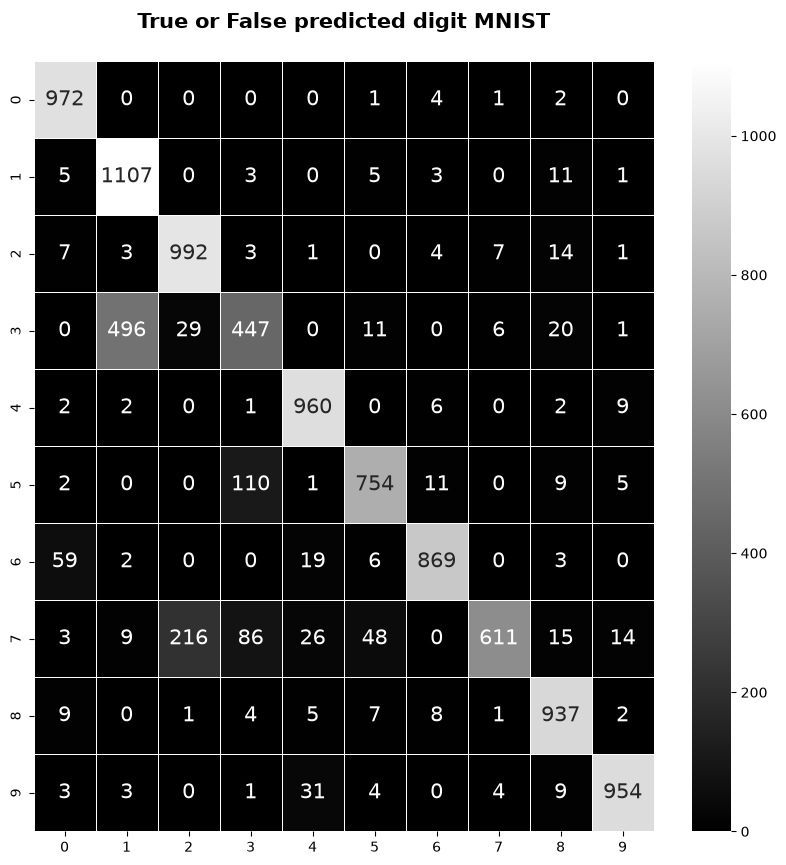

In [29]:
#Confusion matrix for Digit MNIST
con_mat=confusion_matrix(y_test_digit_eval,y_predicts)   # (actual, predicted) -> 10x10 table
plt.style.use('seaborn-v0_8-deep')     # chart style (old matplotlib name was 'seaborn-deep')
plt.figure(figsize=(10,10))
sns.heatmap(con_mat,
            annot=True,                # write the count inside each box
            annot_kws={'size': 15},    # font size of the counts
            linewidths=0.5,            # thin lines between boxes
            fmt="d",                   # show as whole numbers
            cmap="gray")               # grayscale colours
plt.title('True or False predicted digit MNIST\n',fontweight='bold',fontsize=15)
plt.show()

In [30]:
from sklearn.metrics import classification_report

# Precision, recall, f1-score for each digit + overall accuracy
print(classification_report(y_test_digit_eval,y_predicts))
# NOTE: overall accuracy here (0.88) is lower than model.evaluate (0.9575).
# Likely reason: with sigmoid, many scores hit exactly 1.0 (see y_predict[0]);
# when there's a tie, argmax picks the FIRST index, so some predictions go wrong.
# Using softmax (and scaling pixels /255) avoids this.

              precision    recall  f1-score   support

           0       0.92      0.99      0.95       980
           1       0.68      0.98      0.80      1135
           2       0.80      0.96      0.87      1032
           3       0.68      0.44      0.54      1010
           4       0.92      0.98      0.95       982
           5       0.90      0.85      0.87       892
           6       0.96      0.91      0.93       958
           7       0.97      0.59      0.74      1028
           8       0.92      0.96      0.94       974
           9       0.97      0.95      0.96      1009

    accuracy                           0.86     10000
   macro avg       0.87      0.86      0.86     10000
weighted avg       0.87      0.86      0.85     10000



## 12. Training curves

In [31]:
# history.history is a dictionary - shows what was recorded every epoch
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


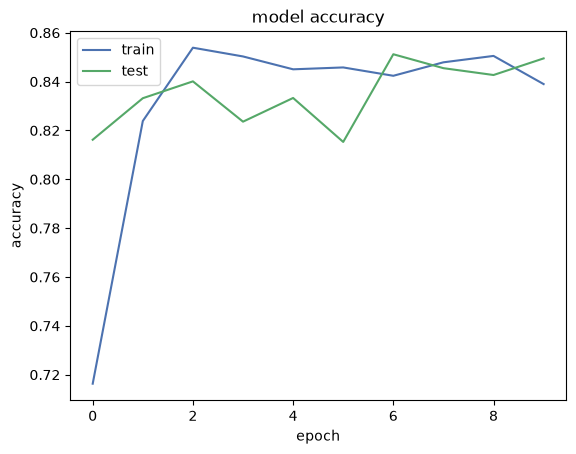

In [32]:
# ---- Accuracy curve: train vs test for every epoch ----
plt.plot(history.history['accuracy'])       # training accuracy per epoch
plt.plot(history.history['val_accuracy'])   # validation (test) accuracy per epoch
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='best')
plt.show()
# Both lines going UP together  = model is learning well
# Train UP but test FLAT/DOWN   = overfitting (memorising training data)

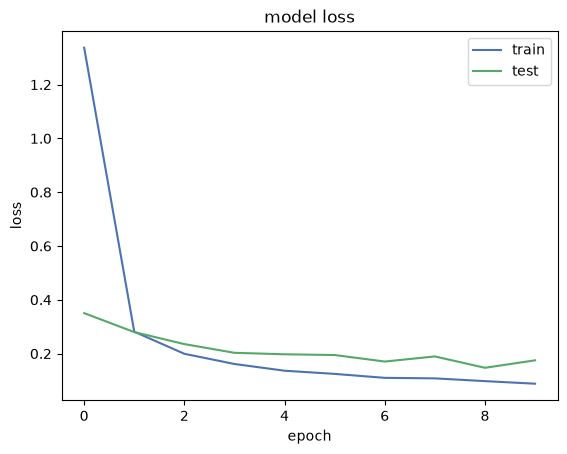

In [33]:
# ---- Loss curve: train vs test for every epoch ----
plt.plot(history.history['loss'])       # training loss (error) per epoch
plt.plot(history.history['val_loss'])   # validation (test) loss per epoch
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='best')
plt.show()
# Loss should go DOWN. If val_loss starts going UP while train loss goes down -> overfitting.

## 13. Predict a single image
The model always expects a **batch** as input (2D: rows × 784), even for a single image.
So `X_test_digit[[2]]` (double brackets) gives shape `(1, 784)`. A single bracket `X_test_digit[2]` gives `(784,)`, which causes an error.

In [34]:
#tf.expand_dims(X_test_digit[0])          # another way to add the batch dimension
y_predict_single = model.predict(X_test_digit[[2]])          # [[2]] keeps it 2D: shape (1, 784)
y_predicts_single=np.argmax(y_predict_single, axis=1) # Here we get the index of maximum value in the encoded vector
y_test_digit_eval=np.argmax(y_test_digit, axis=1)     # actual labels as numbers (same as before)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


In [35]:
# Predicted digit for test image no. 2
y_predicts_single[0]

np.int64(1)

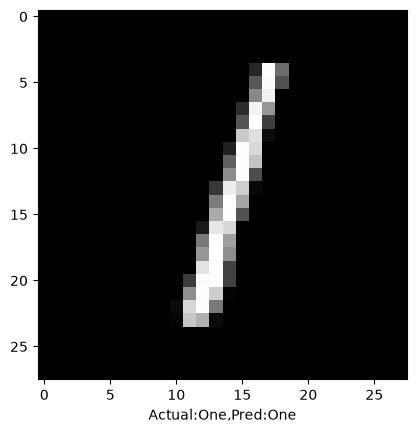

In [36]:
#Names of numbers in the dataset in order
col_names = ['Zero','One','Two','Three','Four','Five','Six','Seven','Eight','Nine']

#Visualizing the digits
#plt.figure(figsize=(10,10))
plt.imshow(X_test_digit[2].reshape(28,28), cmap='gray')   # 784 numbers back to 28x28 picture
plt.xlabel("Actual:{},Pred:{}".format(col_names[np.argmax(y_test_digit[2])],   # real answer
                                      col_names[y_predicts_single[0]]))        # model's answer
plt.show()

In [37]:
# One-hot label of test image no. 8 -> 1 is at index 5, so the digit is 5
y_test_digit[8]

array([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.])

## 14. Summary & next steps
| | Result |
|---|---|
| Test accuracy (`model.evaluate`) | **95.75 %** |
| Hardest digits (classification report) | 3, 5 (low precision/recall) |

**Ideas to improve:**
1. Scale pixels to the 0–1 range with `/255.0`.
2. Change the output layer to `activation='softmax'`.
3. Un-comment the Dropout(0.3) lines to reduce overfitting.
4. Train for more epochs and add an `EarlyStopping` callback.